# The session

Every function of Spatialize reads a few settings from the *session* rather than from its own
arguments, so that they are set once for a whole notebook or script. Here we go through them
with the Walker Lake elevation of the previous tutorial, showing which settings only change how a
result is computed or shown and which change the result itself.

## What you will learn

- How to set, override, read and reset the settings, and how a result records them.
- How to use every processor without changing a single bit of the result.
- How to quiet the progress bars and choose the messages.
- How seeds make a result reproducible.
- What the domain of the partitions is, and why fixing it matters when the queries change.
- What happens in cells without data, the one setting that changes what is estimated.

*Which settings apply to every call, and which of them change my results?*

## The idea

The settings fall into two kinds. Most of them, such as the number of threads, the progress bars and
the messages, change only *how* a result is computed or shown. Spatialize guarantees that these never
change the numbers, bit for bit. Two of them, the box on which the partitions are drawn (`domain`) and
the treatment of cells that hold no datum (`empty_cells`), change *what* is computed. Each result keeps the
settings it was computed with, so a saved result can always be traced back to them.

## Step by step

### The settings and how to set them

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import spatialize
from spatialize.data import load_elevation_walker_lake
from spatialize.gs.esi import esi_griddata, esi_nongriddata

session = spatialize.session
session.show()

domain,None,default
parallel,True,default
num_threads,None,default
empty_cells,'nan',default
mark_source,'local',default
mark_knn,8,default
mark_value,'decoder',default
max_left_out,0.05,default
display,'auto',default
verbosity,'warning',default
progress,True,default


`show()` lists every setting with its value. Three functions change them.

- `session.set(name=value)` keeps the value until it is changed or reset.
- `with session.override(name=value):` sets it inside the block only, and restores it on exit, also
  when the block fails.
- `session.reset()` returns every setting, or the ones named, to its default.

`session.get(name)` reads one value.

In [2]:
samples, grid = load_elevation_walker_lake()
points, values = samples[["x", "y"]].values, samples["elevation"].values
xs, ys = np.sort(grid["x"].unique()), np.sort(grid["y"].unique())
xi = np.stack(np.meshgrid(xs, ys, indexing="ij"))
settings = dict(local_interpolator="adaptiveidw", n_partitions=50, alpha=0.95, seed=0)

We use the adaptive IDW with 50 partitions throughout, on the 780 data and the 260 × 300 grid of the
first tutorial.

### Threads, without changing the result

`parallel` (on by default) runs the partitions on several threads, as many as `num_threads` says or,
by default, every processor. Each partition writes its own column of members, so the result does not
depend on the number of threads.

In [3]:
with session.override(progress=False):
    start = time.perf_counter()
    on_all = esi_griddata(points, values, xi, **settings)
    t_all = time.perf_counter() - start
    with session.override(parallel=False):
        start = time.perf_counter()
        on_one = esi_griddata(points, values, xi, **settings)
        t_one = time.perf_counter() - start
same = np.array_equal(on_all.esi_samples(), on_one.esi_samples(), equal_nan=True)
print(f"every processor {t_all:.1f} s, one thread {t_one:.1f} s, identical members {same}")

every processor 1.6 s, one thread 22.1 s, identical members True


The members are identical bit for bit, so parallelism is a matter of time only. Inside a `with` block
the setting applies to that block alone, here also hiding the progress bars.

### Progress bars and messages

Three settings shape what Spatialize prints, none of them the numbers.

- `display` chooses the look, `"auto"` (the default) detecting a notebook, a terminal or a log,
  `"plain"` writing plain lines and `"silent"` showing nothing.
- `progress` turns the bars on or off while keeping the messages.
- `verbosity` sets the lowest level of the messages shown, `"warning"` by default, or `"info"` and
  `"debug"` for more, `"error"` for less.

The plain look, for instance, writes a line at every quarter of the work, which suits a log.

In [4]:
with session.override(display="plain"):
    esi_nongriddata(points, values, np.array([[4.05, 15.05]]), **settings)

spatialize | computing optimal parameters · mondrian/adaptiveidw: started, 50 steps
spatialize | computing optimal parameters · mondrian/adaptiveidw: 25% (13/50, 1s)
spatialize | computing optimal parameters · mondrian/adaptiveidw: 50% (25/50, 1s)
spatialize | computing optimal parameters · mondrian/adaptiveidw: 75% (38/50, 1s)
spatialize | computing optimal parameters · mondrian/adaptiveidw: done, 50 in 1.5s
spatialize | computing estimates · mondrian/adaptiveidw: started, 50 steps
spatialize | computing estimates · mondrian/adaptiveidw: 25% (13/50, 0s)
spatialize | computing estimates · mondrian/adaptiveidw: 50% (25/50, 0s)
spatialize | computing estimates · mondrian/adaptiveidw: 75% (38/50, 0s)
spatialize | computing estimates · mondrian/adaptiveidw: done, 50 in 0.0s


### Seeds

The partitions are random. The argument `seed` fixes them, so the same call gives the same result.
Without it, Spatialize draws a seed at every call.

In [5]:
with session.override(progress=False):
    again = esi_griddata(points, values, xi, **settings)
    other = esi_griddata(points, values, xi, **{**settings, "seed": 1})
print(f"same seed, identical estimate {np.array_equal(on_all.estimation(), again.estimation())}")
difference = np.abs(on_all.estimation() - other.estimation())
print(f"another seed, mean difference {difference.mean():.1f} m, largest {difference.max():.0f} m")

same seed, identical estimate True
another seed, mean difference 8.5 m, largest 146 m


Another seed draws other partitions, so the map changes a little, by a few metres on average. With
50 partitions that change is part of the uncertainty of the map, and more partitions shrink it (the
tutorial *How many partitions?* measures it).

### The domain of the partitions

The partitions are drawn on a box. By default (`domain=None`) it is the smallest box holding the data
and the queries of each call, so a query far from the data enlarges it, changing the partitions. The
granularity `alpha` is measured on the box of the data alone, so the cells keep their size, but the
members at a location are not the same any more.

In [6]:
here = np.array([[4.05, 15.05]])
with_far = np.array([[4.05, 15.05], [40.0, 45.0]])
with session.override(progress=False):
    alone = esi_nongriddata(points, values, here, **settings).esi_samples()[0]
    together = esi_nongriddata(points, values, with_far, **settings).esi_samples()[0]
    print(f"without a domain, the same members {np.array_equal(alone, together, equal_nan=True)}")
    with session.override(domain=[[0, 45], [0, 50]]):
        alone = esi_nongriddata(points, values, here, **settings).esi_samples()[0]
        together = esi_nongriddata(points, values, with_far, **settings).esi_samples()[0]
    print(f"with a fixed domain, the same members {np.array_equal(alone, together, equal_nan=True)}")

without a domain, the same members False
with a fixed domain, the same members True


With the domain fixed, a location gets the same members whatever else is asked for, so estimates made
in several calls (tiles of a large grid, new locations added later) fit together exactly. Every datum
and query must lie in the domain. Under the default Mondrian process the *law* at a location does not
depend on the other queries anyway, only its particular members do.

### Cells without data

At fine granularities many cells hold no datum. `empty_cells` decides what a location in such a cell
gets from that partition, and unlike the settings above it changes the law that is estimated.

- `"nan"`, the default, gives no member. The estimate at the location rests on the partitions whose
  cell holds data.
- `"mark"` gives the cell one value drawn from cells with data, as the theory's block-mark model does.
  `mark_source`, `mark_knn` and `mark_value` say where the value comes from.
- `"coarsen"` predicts the location from the nearest coarser cell that holds data.

`empty_cell_fraction()` gives, at every location, the share of partitions whose cell held no datum.

members left undefined by 'nan' 47%
locations left without any member by 'nan' 2 of 78000
"mark" against "nan", mean change 20.2 m, largest 494 m
"coarsen" against "nan", mean change 15.5 m, largest 519 m


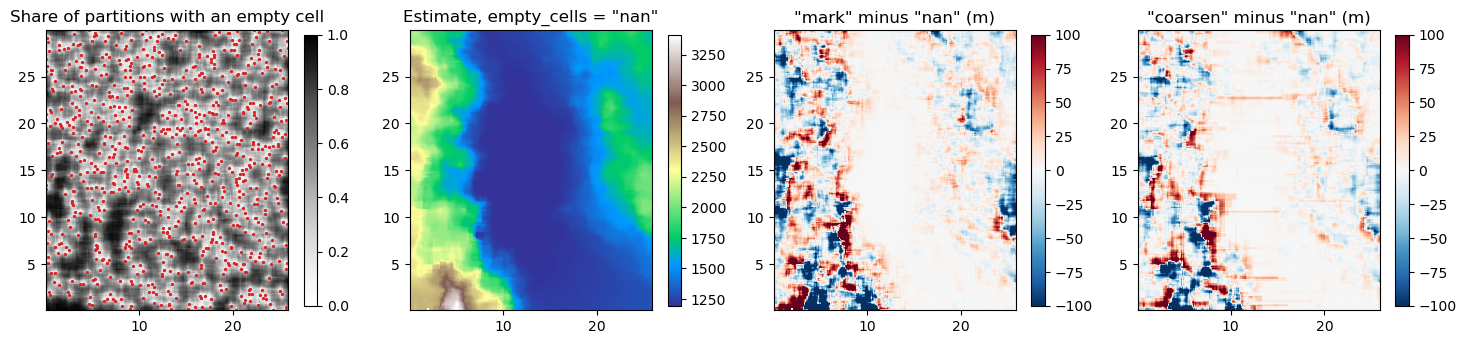

In [7]:
fine = {**settings, "alpha": 0.99}
results = {}
with session.override(progress=False):
    for policy in ("nan", "mark", "coarsen"):
        with session.override(empty_cells=policy):
            results[policy] = esi_griddata(points, values, xi, **fine)
fraction = results["nan"].empty_cell_fraction()
print(f"members left undefined by 'nan' {np.isnan(results['nan'].esi_samples()).mean():.0%}")

base = results["nan"].estimation()
print(f"locations left without any member by 'nan' {np.isnan(base).sum()} of {base.size}")
for policy in ("mark", "coarsen"):
    change = np.abs(results[policy].estimation() - base)
    print(f'"{policy}" against "nan", mean change {np.nanmean(change):.1f} m, largest {np.nanmax(change):.0f} m')

extent = (xs[0], xs[-1], ys[0], ys[-1])
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
im = axes[0].imshow(fraction.T, origin="lower", extent=extent, cmap="Greys", vmin=0, vmax=1)
axes[0].scatter(points[:, 0], points[:, 1], s=2, c="C3")
axes[0].set_title("Share of partitions with an empty cell")
fig.colorbar(im, ax=axes[0], shrink=0.8)
im = axes[1].imshow(base.T, origin="lower", extent=extent, cmap="terrain")
axes[1].set_title('Estimate, empty_cells = "nan"')
fig.colorbar(im, ax=axes[1], shrink=0.8)
for ax, policy in zip(axes[2:], ("mark", "coarsen")):
    im = ax.imshow((results[policy].estimation() - base).T, origin="lower", extent=extent, cmap="RdBu_r",
                   vmin=-100, vmax=100)
    ax.set_title(f'"{policy}" minus "nan" (m)')
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

At this granularity about half of the members fall in empty cells, more away from the data, while a
few locations get no member at all under `"nan"`. Filling the empty cells changes the map by 15 to 20 m on
average and by several hundred metres at worst, on the slopes, where the data around an empty cell
differ. On the flat lake every policy gives the same value. Cross-validation feels the difference most. Under `"nan"` a datum
alone in its cell has no prediction and drops out of the score, so the searches warn when the share
left out passes `max_left_out`. The gallery's tutorials set `empty_cells="coarsen"` for that reason.

### What a result remembers

Every result keeps the settings in effect when it was computed, in `effective_config`, and
`spatialize.data.save_result` stores them with it.

In [8]:
results["coarsen"].effective_config

{'domain': None,
 'parallel': True,
 'num_threads': None,
 'empty_cells': 'coarsen',
 'mark_source': 'local',
 'mark_knn': 8,
 'mark_value': 'decoder',
 'max_left_out': 0.05,
 'display': 'auto',
 'verbosity': 'warning',
 'progress': False}

### Stopping a long run

A long estimation or search can be stopped with the notebook's *interrupt* button (Ctrl-C in a
terminal). The compiled engine checks for it between partitions and raises `KeyboardInterrupt`,
leaving the session and the previous results as they were.

In [9]:
session.reset()

## What can go wrong

- **Results that differ between two runs.** A call without `seed` draws a new one every time. Pass the
  seed when a result must be reproduced.
- **Estimates that do not join.** Estimating a large grid in pieces, or adding locations later, gives
  members that do not match without a fixed `domain`.
- **A setting left on.** `session.set` lasts until it is changed. Prefer `session.override` in a `with`
  block for anything temporary, and `session.show()` to see what is in effect.
- **Comparing results computed under different `empty_cells`.** They estimate different laws. Check
  `effective_config` before comparing.

## Try it yourself

1. Time `esi_griddata` with `num_threads` set to 1, 2, 4 and every processor, and check the members are
   identical each time.
2. Estimate the grid in two halves with a fixed `domain` and compare with one call over the whole grid.
3. Under `empty_cells="mark"`, try `mark_source="cells"` and `mark_value="datum"`, the block-mark model
   exactly, and compare the maps.

## Next

- *A first ensemble map*, the tutorial these settings were used in.
- *Cells without data*, for `empty_cells` and the marks in depth.
- *Choosing an ensemble with the Pareto search*, where `empty_cells="coarsen"` keeps every datum in the
  score.
- The documentation's [session reference](https://spatialize.readthedocs.io/en/latest/reference/session.html).